1. M1 (Return / Price Direction Prediction)

Focus: Predict future return values or directional price movement.

Question answered: "By what percentage will the price rise/fall over the next 7 days?"

Models tested: Naive (historical mean), ARIMA, and XGBoost Regressor.

Evaluation Metrics: MAE (Mean Absolute Error) and Directional Accuracy (up/down hit rate).

Nature: Hardest to predict in financial markets because daily price movements are highly noisy and closely approximate a random walk.

---

2. M2 (Volatility / Risk Prediction)

Focus: Predict the magnitude of future price fluctuations (variance), regardless of whether the price moves up or down.

Question answered: "How volatile/risky will this stock be over the next 7 days?"

Models tested: Naive, GARCH(1,1), and XGBoost Regressor (predicting squared returns).

Evaluation Metric: QLIKE (quasi-likelihood metric tailored for variance/volatility evaluation).

Nature: More predictable than M1 because volatility exhibits memory (volatility clustering — volatile days tend to be followed by volatile days).

---

3. M3 (Early Warning Classification / Correction Probability)

Focus: Predict the probability of a specific extreme event — namely, a price drop (correction) exceeding a defined threshold (e.g., dropping more than -3%).

Question answered: "What is the risk of the price dropping by more than -3% over the next 7 days?"

Model tested: XGBoost Classifier.

Evaluation Metrics: AUC (Area Under Curve), Log Loss, and Accuracy.

Nature: Acts as an early warning system to protect portfolios before a deep drawdown occurs.

---

In short:
M1 predicts direction and magnitude, M2 predicts risk level, and M3 predicts crash probability.

In [1]:
!pip install arch
# !pip install arch yfinance statsmodels sklearn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 8.5 MB/s  0:00:00

In [2]:
import pandas as pd
import numpy as np
import yfinance as yf
import xgboost as xgb
import os, json, joblib
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.arima.model import ARIMA
from arch import arch_model
from sklearn.metrics import mean_absolute_error, mean_squared_error, log_loss, roc_auc_score, accuracy_score

import warnings
warnings.filterwarnings("ignore")

print("yfinance", yf.__version__)

T = ["TLKM","GOTO","DCII"]

# Parse dates (Indonesian + English month abbreviations in the CSV)
M = {"Jan":1,"Feb":2,"Mar":3,"Apr":4,"Mei":5,"May":5,"Jun":6,"Jul":7,
     "Agt":8,"Agu":8,"Aug":8,"Sep":9,"Okt":10,"Oct":10,"Nov":11,"Des":12,"Dec":12}

yfinance 0.2.66

In [3]:
!test -f indonesia-stock-exchange-idx-historical-price || kaggle datasets download -d eren2222/indonesia-stock-exchange-idx-historical-price --unzip

Dataset URL: https://www.kaggle.com/datasets/eren2222/indonesia-stock-exchange-idx-historical-price
License(s): CC0-1.0
100% 54.5M/54.5M [00:00<00:00, 64.3MB/s]


In [4]:
!ls

'IDX Stock Summary 2020-2024.csv'   sample_data

In [5]:
df= pd.read_csv("./IDX Stock Summary 2020-2024.csv")

print(df.shape); df.info(); print(df.head(3).T)
print(df.columns.tolist())
for c in df.columns:
    if "date" in c.lower() or "trad" in c.lower():
        print(c, df[c].min(), df[c].max(), df[c].nunique())
t = df[df.iloc[:,1].isin(["TLKM","GOTO","DCII"])]   # Stock Code column
print(t.iloc[:,1].value_counts())

(831622, 28)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 831622 entries, 0 to 831621
Data columns (total 28 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   No                     831622 non-null  int64  
 1   Stock Code             831622 non-null  object 
 2   Company Name           831622 non-null  object 
 3   Remarks                831622 non-null  object 
 4   Previous               831622 non-null  int64  
 5   Open Price             831622 non-null  int64  
 6   Last Trading Date      831622 non-null  object 
 7   First Trade            831622 non-null  int64  
 8   High                   831622 non-null  int64  
 9   Low                    831622 non-null  int64  
 10  Close                  831622 non-null  int64  
 11  Change                 831622 non-null  int64  
 12  Volume                 831622 non-null  int64  
 13  Value                  831622 non-null  int64  
 14  Frequency              

In [6]:
df.head()

,No,Stock Code,Company Name,Remarks,Previous,Open Price,Last Trading Date,First Trade,High,Low,...,Bid,Bid Volume,Listed Shares,Tradeble Shares,Weight For Index,Foreign Sell,Foreign Buy,Non Regular Volume,Non Regular Value,Non Regular Frequency
0,1,AALI,Astra Agro Lestari Tbk.,--S1K--1,14575,0,02 Jan 2020,0,14650,14025,...,14025.0,49900,1.924688e+09,1.924688e+09,1.924688e+09,106300,253800,0.0,0.000000e+00,0
1,2,ABBA,Mahaka Media Tbk.,--U9---2,106,0,02 Jan 2020,0,108,105,...,105.0,786900,2.755125e+09,2.755125e+09,2.755125e+09,21600,0,0.0,0.000000e+00,0
2,3,ABDA,Asuransi Bina Dana Arta Tbk.,--U8---2,6975,0,02 Jan 2020,0,7075,6925,...,5600.0,100,6.208067e+08,6.208067e+08,6.208067e+08,1600,0,0.0,0.000000e+00,0
3,4,ABMM,ABM Investama Tbk.,--U9---1,1530,0,02 Jan 2020,0,0,0,...,1205.0,500,2.753165e+09,2.753165e+09,2.753165e+09,0,0,0.0,0.000000e+00,0
4,5,ACES,Ace Hardware Indonesia Tbk.,--S9KB-1,1495,0,02 Jan 2020,0,1535,1500,...,1510.0,572700,1.715000e+10,1.715000e+10,1.715000e+10,7584400,5264200,51000005.0,7.736701e+10,3


In [7]:
def parse(s):
    d, m, y = s.split()
    return pd.Timestamp(int(y), M[m], int(d))
df["date"] = df["Last Trading Date"].map(parse)
print("ORIGINAL RANGE:", df.date.min().date(), df.date.max().date(), "| unique days:", df.date.nunique())

# Audit universe
g = df.groupby("Stock Code")
u = pd.DataFrame({"rows": g.size(), "unique_dates": g["date"].nunique(),
                  "start": g["date"].min(), "end": g["date"].max(),
                  "vol0_pct": g["Volume"].apply(lambda s: (s == 0).mean())})
print("number of tickers:", len(u)); print(u["unique_dates"].describe())
print("tickers >=900 days & vol0<10%:", ((u.unique_dates >= 900) & (u.vol0_pct < 0.10)).sum())
print("tickers ending before dataset end:", (u.end < df.date.max()).sum())
print(u.loc[["TLKM","GOTO","DCII"]])

# Duplicate check (hypothesis T2)
k = df[df["Stock Code"].isin(["TLKM","GOTO","DCII"])].copy()
dup = k[k.duplicated(["Stock Code","date"], keep=False)].sort_values(["Stock Code","date","No"])
print("duplicate rows for 3 tickers:", len(dup))
print(dup[["No","Stock Code","date","Close","Volume","Frequency","Remarks"]].head(12))
print("duplicates across entire dataset:", df.duplicated(["Stock Code","date"]).sum())

# yfinance raw + adj, excluding today's candle
raw = {}
for t in T:
    x = yf.download(f"{t}.JK", start="2020-01-01", auto_adjust=False, progress=False)
    x.columns = x.columns.get_level_values(0)
    x = x[x.index < "2026-11-11"]
    raw[t] = x
    print(t, len(x), x.index.min().date(), x.index.max().date(),
          "| NaN:", int(x.isna().sum().sum()), "| volume=0:", int((x["Volume"]==0).sum()))

# Cross-check Kaggle vs yfinance (raw Close)
for t in raw:
    kk = k[k["Stock Code"]==t].drop_duplicates("date", keep="last").set_index("date")
    j = kk[["Close","Volume"]].join(raw[t][["Close","Volume"]], lsuffix="_k", rsuffix="_y", how="inner")
    rel = (j["Close_k"]-j["Close_y"]).abs()/j["Close_k"]
    print(t, "overlap", len(j), "| diff>0.5%:", int((rel>0.005).sum()),
          "| diff quantiles 50/95/99%:", rel.quantile([.5,.95,.99]).round(4).tolist(),
          "| median volume ratio k/y:", (j["Volume_k"]/j["Volume_y"]).median())

ORIGINAL RANGE: 2020-01-02 2024-05-16 | unique days: 985
number of tickers: 938
count    938.000000
mean     828.581023
std      287.231637
min        5.000000
25%      833.000000
50%      985.000000
75%      985.000000
max      985.000000
Name: unique_dates, dtype: float64
tickers >=900 days & vol0<10%: 493
tickers ending before dataset end: 9
             rows  unique_dates      start        end  vol0_pct
Stock Code                                                 
TLKM         1055       985 2020-01-02 2024-05-16   0.00000
GOTO          500       471 2022-04-11 2024-05-16   0.00000
DCII          812       760 2021-01-06 2024-05-16   0.20936
duplicate rows for 3 tickers: 263
         No Stock Code       date  Close  Volume  Frequency  \
173263  189       DCII 2021-01-13   1580   30700         32   
173981  189       DCII 2021-01-13   1580   30700         32   
174699  189       DCII 2021-01-13   1580   30700         32   
175417  189       DCII 2021-01-13   1580   30700         32   


In [8]:
k = df[df["Stock Code"].isin(T)].copy()

# Are duplicates strictly identical?
cols = ["Open Price","High","Low","Close","Volume","Value","Frequency","Foreign Buy","Foreign Sell"]
chk = k.groupby(["Stock Code","date"])[cols].nunique()
print("groups with differing values across duplicates:\n", (chk > 1).sum())
kd = k.sort_values("No").drop_duplicates(["Stock Code","date"], keep="first")

# Six days with >0.5% difference
bad = []
for t in T:
    kk = kd[kd["Stock Code"]==t].set_index("date")
    j = kk[["Close","High","Low","Volume"]].join(raw[t][["Close","High","Low","Volume"]],
                                                 lsuffix="_k", rsuffix="_y", how="inner")
    j["rel"] = (j.Close_k - j.Close_y).abs() / j.Close_k
    b = j[j.rel > 0.005].copy(); b.insert(0, "ticker", t); bad.append(b)
print(pd.concat(bad))

# yfinance days missing from Kaggle (up to May 16, 2024)
for t in T:
    y = raw[t][raw[t].index <= "2024-05-16"]
    kdates = set(kd.loc[kd["Stock Code"]==t, "date"])
    miss = y.index[~y.index.isin(kdates)]
    print(t, "yfinance days:", len(y), "| missing in Kaggle:", len(miss),
          "| with volume>0:", int((y.loc[miss, "Volume"] > 0).sum()))

# Corporate actions: jumps in adj/close ratio and extreme returns
for t in T:
    r = raw[t]["Adj Close"] / raw[t]["Close"]
    jump = r.pct_change().abs()
    print(t, "adj/close jump >0.1%:", jump[jump > 0.001].round(4).to_dict())
    lr = np.log(raw[t]["Close"]).diff().abs()
    print(t, "5 largest daily returns:", lr.nlargest(5).round(3).to_dict())

# DCII: zero-volume pattern
d = raw["DCII"]; z = d[d.Volume == 0]
print("DCII vol0:", len(z), "| O=H=L=C:",
      int(((z.Open==z.High)&(z.High==z.Low)&(z.Low==z.Close)).sum()),
      "| per year:", z.groupby(z.index.year).size().to_dict())

# Save canonical
frames = []
for t, x in raw.items():
    c = x.rename(columns={"Open":"open","High":"high","Low":"low","Close":"close",
                          "Adj Close":"adj_close","Volume":"volume"})[
        ["open","high","low","close","adj_close","volume"]].copy()
    c.index.name = "trade_date"; c = c.reset_index()
    c["instrument_id"] = f"IDX:{t}"; c["currency"] = "IDR"
    c["source"] = "yfinance"; c["is_traded"] = c["volume"] > 0
    frames.append(c)
can = pd.concat(frames, ignore_index=True)
can.to_parquet("canonical.parquet", index=False)
print(can.groupby("instrument_id").agg(n=("close","size"), start=("trade_date","min"),
                                       end=("trade_date","max"), traded=("is_traded","sum")))

groups with differing values across duplicates:
 Open Price      0
High            0
Low             0
Close           0
Volume          0
Value           0
Frequency       0
Foreign Buy     0
Foreign Sell    0
dtype: int64
           ticker  Close_k  High_k  Low_k    Volume_k  Close_y   High_y  \
2020-03-13   TLKM     3390    3490   3080   172248400   3310.0   3310.0   
2024-01-15   GOTO       92      92     90  1514483800     91.0     91.0   
2024-03-26   GOTO       70      71     68  2963091300     68.0     68.0   
2024-03-25   GOTO       69      69     67  1659401900     68.0     68.0   
2022-03-14   DCII    44000   44000  43400        5500  43450.0  43450.0   
2024-03-26   DCII    35500   35600  35475        1700  35825.0  35825.0   

              Low_y  Volume_y       rel  
2020-03-13   3310.0         0  0.023599  
2024-01-15     91.0         0  0.010870  
2024-03-26     68.0         0  0.028571  
2024-03-25     68.0         0  0.014493  
2022-03-14  43450.0         0  0.012500 

In [9]:
# All yfinance vol=0 days recorded as traded in Kaggle (not just >0.5% diff)
fix = {}
for t in T:
    kk = kd[kd["Stock Code"]==t].set_index("date")
    j = raw[t].join(kk[["First Trade","High","Low","Close","Volume"]], how="inner", rsuffix="_k")
    m = j[(j["Volume"]==0) & (j["Volume_k"]>0)]
    fix[t] = m
    print(t, "days repaired:", len(m))
    print(m[["Close","Close_k","High_k","Low_k","Volume_k","First Trade"]])

# Build repaired series
rep = {}
for t in T:
    y = raw[t].copy(); y["source"] = "yfinance"
    for d, r in fix[t].iterrows():
        f = y.at[d,"Adj Close"] / y.at[d,"Close"]
        o = r["First Trade"] if r["First Trade"] > 0 else np.nan
        y.loc[d, ["Open","High","Low","Close","Volume"]] = [o, r["High_k"], r["Low_k"], r["Close_k"], r["Volume_k"]]
        y.at[d,"Adj Close"] = r["Close_k"] * f
        y.at[d,"source"] = "kaggle_repair"
    y["Open"] = y["Open"].fillna(y["Close"].shift(1))
    rep[t] = y

# Official corporate actions from yfinance
for t in T:
    tk = yf.Ticker(f"{t}.JK")
    print(t, "dividends:", tk.dividends.tail(8).round(2).to_dict() if len(tk.dividends) else "-",
          "| splits:", tk.splits.to_dict() if len(tk.splits) else "-")

# SIGNED extreme returns with surrounding context
chk = {"TLKM": ["2026-01-28","2026-06-08","2026-10-16","2026-10-20"],
       "DCII": ["2025-03-14","2025-03-17","2025-03-18"]}
for t, dts in chk.items():
    y = rep[t]; r = y["Close"].pct_change()
    for d in dts:
        i = y.index.get_loc(pd.Timestamp(d))
        print(f"\n{t} {d} return={r.iloc[i]:+.4f}")
        print(y.iloc[i-1:i+2][["Open","High","Low","Close","Volume"]])

# Save canonical v2 (overwrites v1)
frames = []
for t, y in rep.items():
    c = y.rename(columns={"Open":"open","High":"high","Low":"low","Close":"close",
                          "Adj Close":"adj_close","Volume":"volume"})[
        ["open","high","low","close","adj_close","volume","source"]].copy()
    c.index.name = "trade_date"; c = c.reset_index()
    c["instrument_id"] = f"IDX:{t}"; c["currency"] = "IDR"
    c["is_traded"] = c["volume"] > 0
    c["adj_factor"] = c["adj_close"] / c["close"]
    frames.append(c)
can = pd.concat(frames, ignore_index=True)
assert not can.duplicated(["instrument_id","trade_date"]).any()
bad = can[(can.low > can.high) | (can.close > can.high + 1e-6) | (can.close < can.low - 1e-6)]
print("inconsistent OHLC rows:", len(bad))
can.to_parquet("canonical.parquet", index=False)
print(can.groupby("instrument_id").agg(n=("close","size"), traded=("is_traded","sum"),
      repair=("source", lambda s: (s=="kaggle_repair").sum())))

TLKM days repaired: 1
             Close  Close_k  High_k  Low_k   Volume_k  First Trade
2020-03-13  3310.0     3390    3490   3080  172248400            0
GOTO days repaired: 3
            Close  Close_k  High_k  Low_k    Volume_k  First Trade
2024-01-15   91.0       92      92     90  1514483800           91
2024-03-25   68.0       69      69     67  1659401900           69
2024-03-26   68.0       70      71     68  2963091300           69
DCII days repaired: 4
              Close  Close_k  High_k  Low_k  Volume_k  First Trade
2022-03-14  43450.0    44000   44000  43400      5500            0
2024-01-15  40000.0    39950   40000  39950      1300            0
2024-03-25  35825.0    35800   35825  35800       500            0
2024-03-26  35825.0    35500   35600  35475      1700            0
TLKM dividends: {Timestamp('2019-06-12 00:00:00+0700', tz='Asia/Jakarta'): 163.82, Timestamp('2020-06-30 00:00:00+0700', tz='Asia/Jakarta'): 154.07, Timestamp('2021-06-09 00:00:00+0700', tz='Asia/J

TLKM: weekdays without rows: 137 | longest gap (days): 12
GOTO TLKM calendar days missing: 0 | present in ticker but not in TLKM: 0
DCII TLKM calendar days missing: 0 | present in ticker but not in TLKM: 0
ticker    n   daily_std   annual_vol   skew  kurtosis     min    max   maxDD  pct_traded  big_move
  TLKM 1651      0.0218       0.3410 0.0226    7.7890 -0.1608 0.1517 -0.5193      1.0000        30
  GOTO 1095      0.0381       0.5961 0.6161    7.3504 -0.2278 0.2991 -0.9431      1.0000        20
  DCII 1407      0.0430       0.6724 1.9832   11.0387 -0.2231 0.2231 -0.5929      0.8473        56
TLKM h=7 thr_apriori=5% | base_rate_init_500: 0.164 | full_sample: 0.193 (n=1644)
TLKM h=30 thr_apriori=10% | base_rate_init_500: 0.186 | full_sample: 0.229 (n=1621)
TLKM Ljung-Box p (lag10,20) return: [0.0, 0.0] | return^2: [0.0, 0.0]
GOTO h=7 thr_apriori=10% | base_rate_init_500: 0.210 | full_sample: 0.171 (n=969)
GOTO h=30 thr_apriori=20% | base_rate_init_500: 0.324 | full_sample: 0.234 (n=94

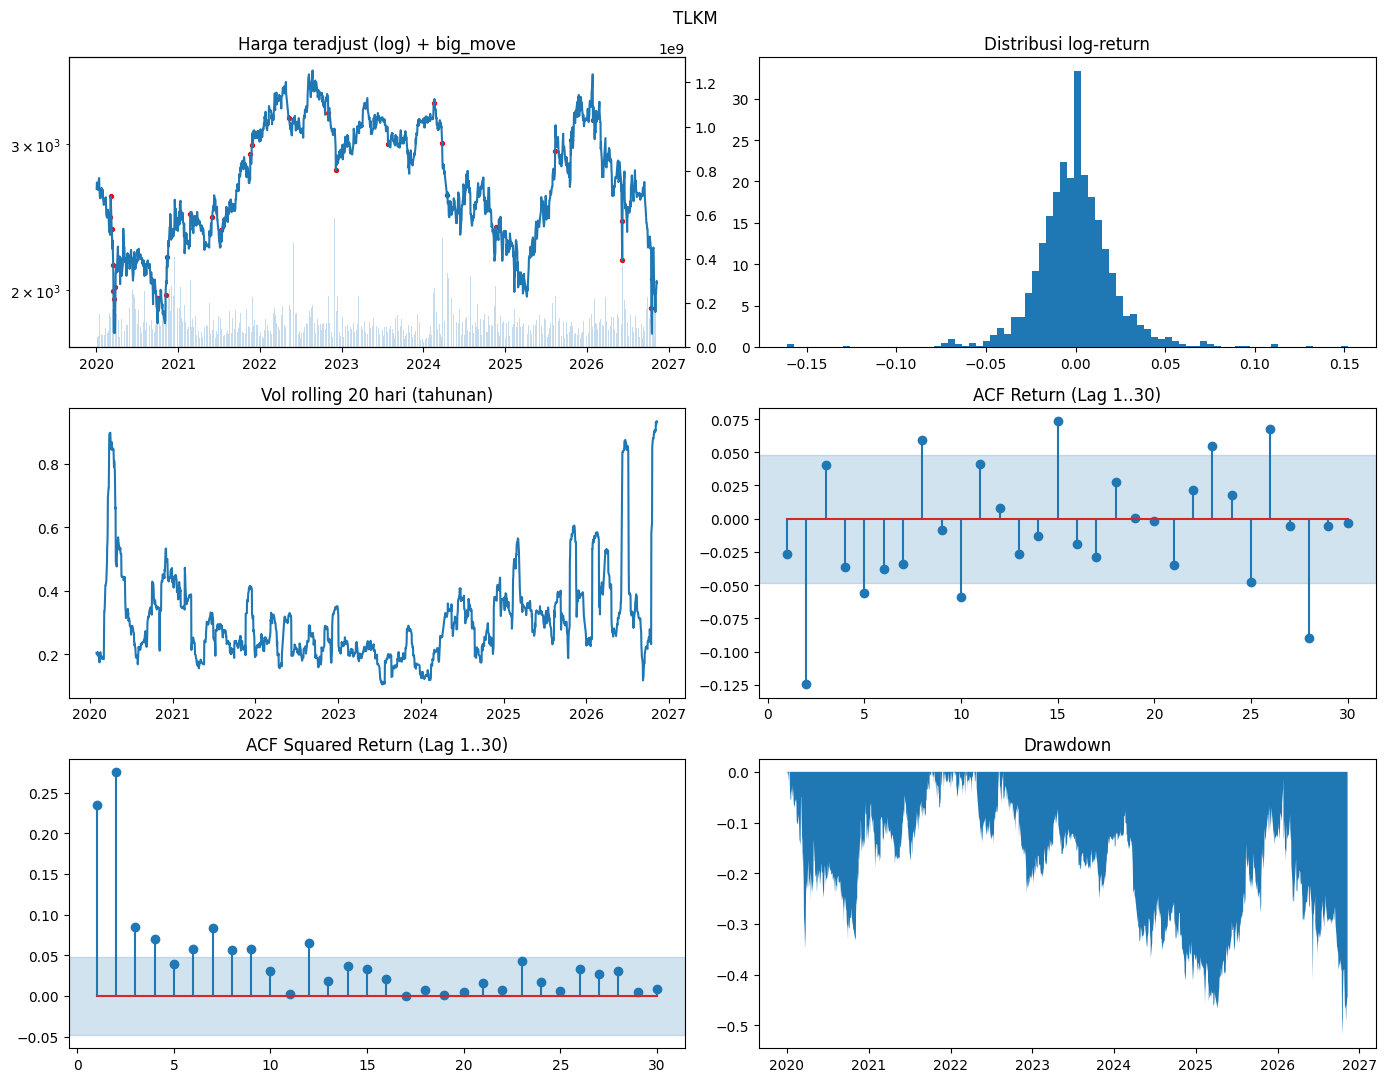

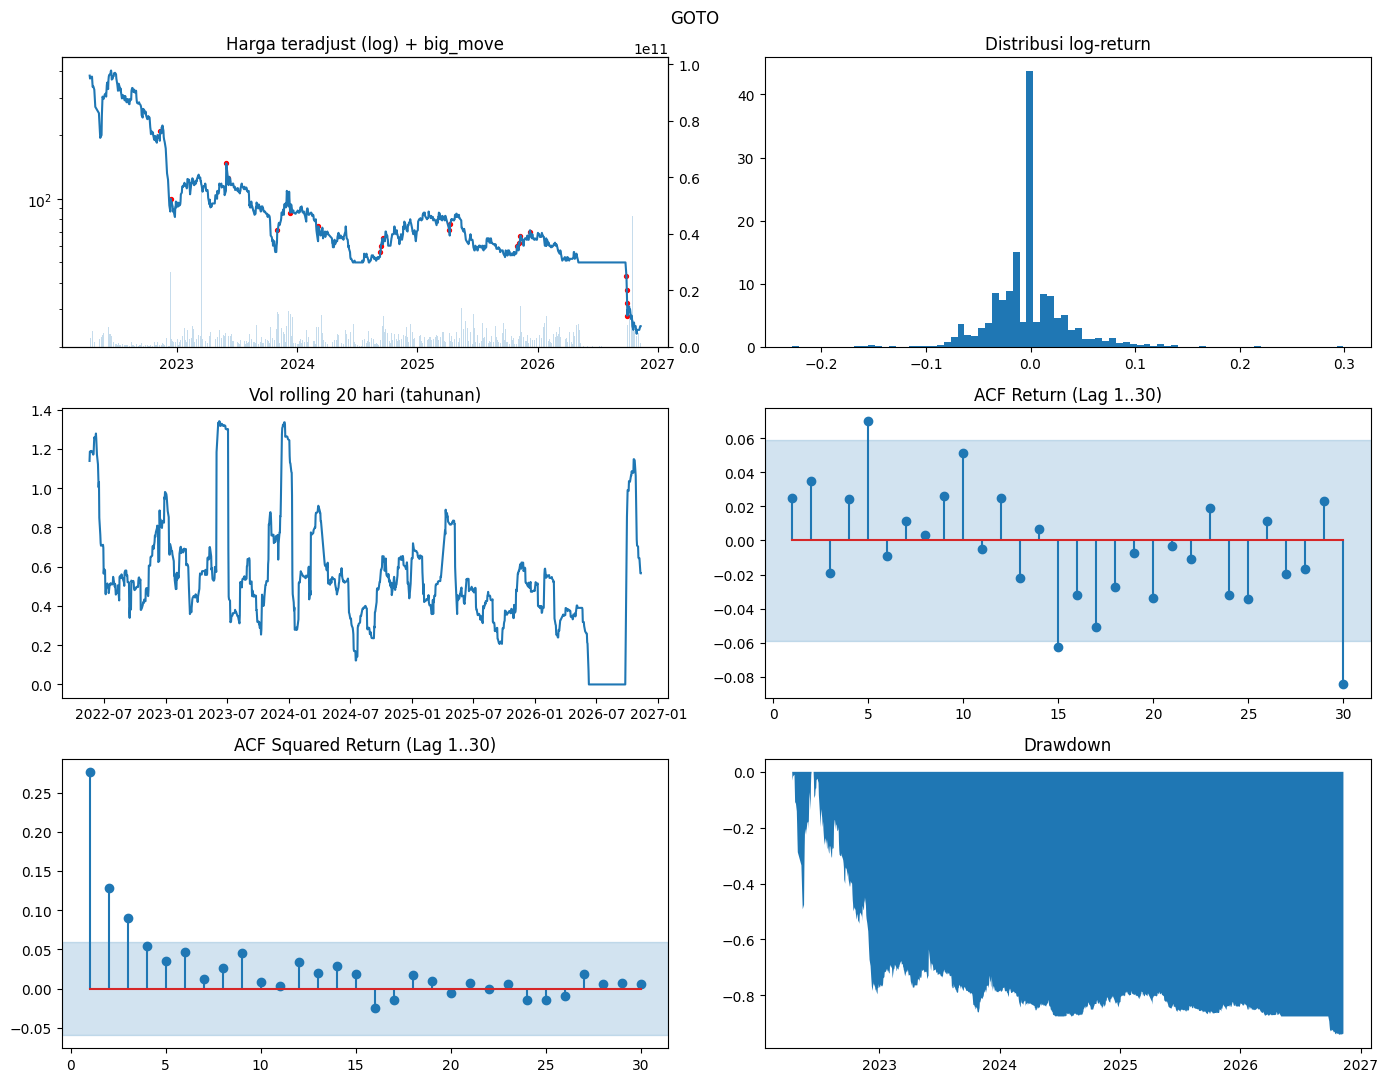

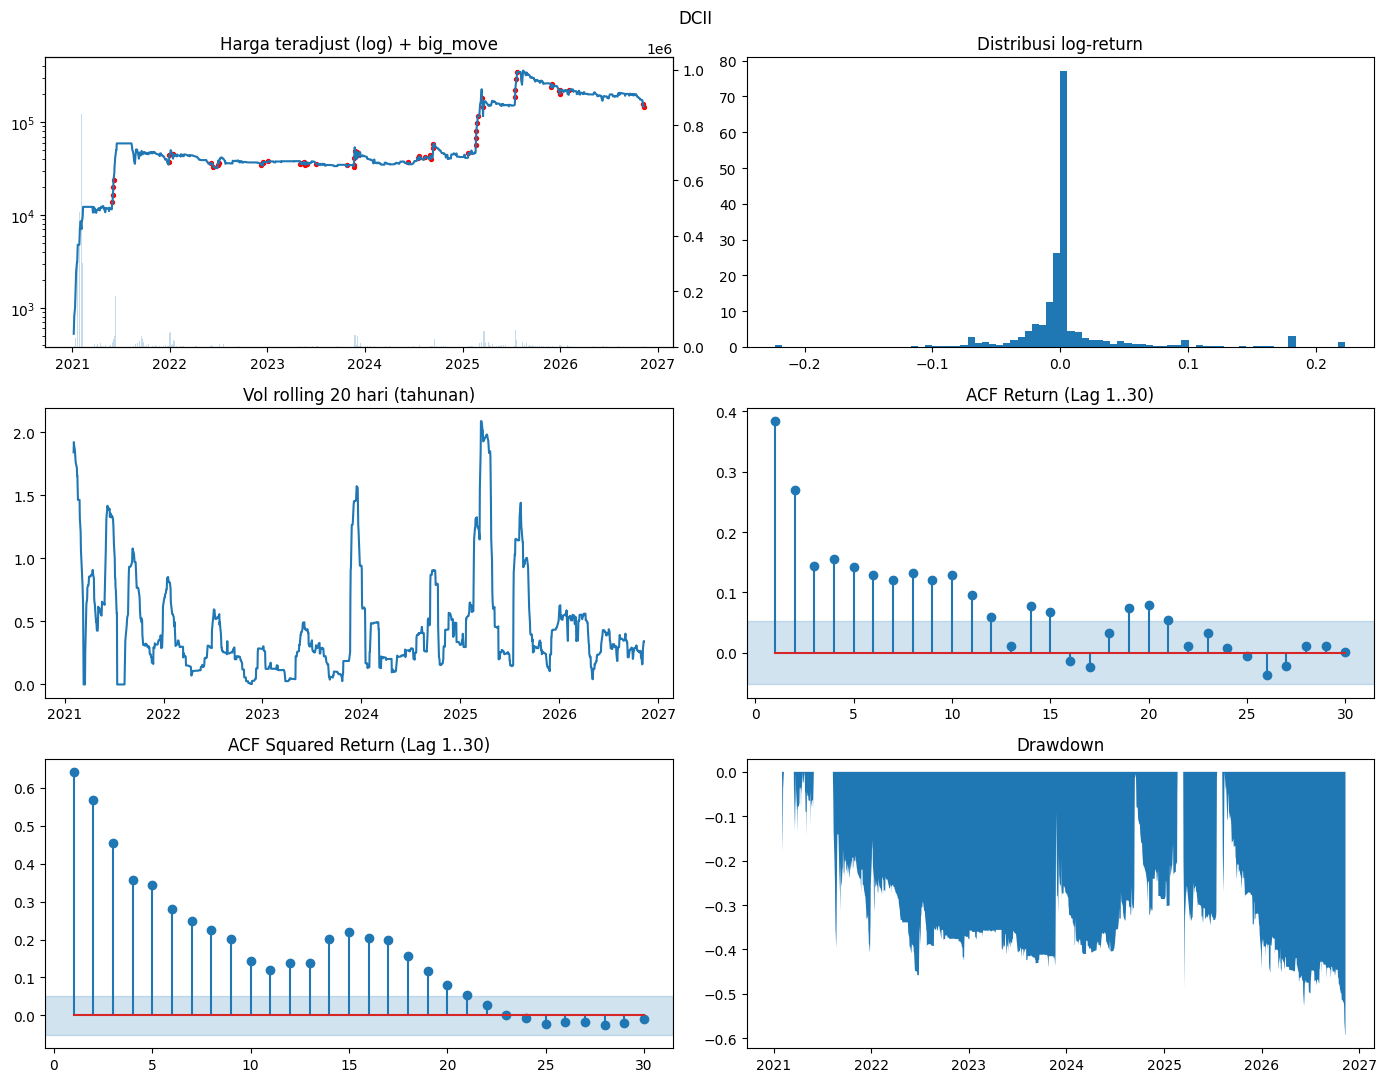

In [10]:
can = pd.read_parquet("canonical.parquet")

# Adjusted OHLC + returns
D = {}
for t in T:
    x = can[can.instrument_id==f"IDX:{t}"].sort_values("trade_date").set_index("trade_date")
    f = x["adj_close"] / x["close"]
    a = pd.DataFrame({"open": x.open*f, "high": x.high*f, "low": x.low*f,
                      "close": x.adj_close, "raw_close": x.close,
                      "volume": x.volume, "traded": x.is_traded})
    a["ret"] = np.log(a.close).diff()
    # big_move flag: uses strictly PRIOR data (shift(1))
    sd = a.ret.rolling(60, min_periods=20).std().shift(1)
    a["big_move"] = a.ret.abs() > 3 * sd
    a["dd"] = a.close / a.close.cummax() - 1
    D[t] = a

# Missing days: reference calendar = TLKM dates (almost always traded)
ref = D["TLKM"].index
bd = pd.bdate_range(ref.min(), ref.max())
gaps = bd.difference(ref)
print("TLKM: weekdays without rows:", len(gaps), "| longest gap (days):",
      int(pd.Series(ref).diff().dt.days.max()))
for t in ["GOTO","DCII"]:
    r = ref[ref >= D[t].index.min()]
    print(t, "TLKM calendar days missing:", len(r.difference(D[t].index)),
          "| present in ticker but not in TLKM:", len(D[t].index.difference(ref)))

# Summary statistics
rows = []
for t, a in D.items():
    r = a.ret.dropna()
    rows.append({"ticker": t, "n": len(r), "daily_std": r.std(), "annual_vol": r.std()*np.sqrt(245),
                 "skew": r.skew(), "kurtosis": r.kurt(), "min": r.min(), "max": r.max(),
                 "maxDD": a.dd.min(), "pct_traded": a.traded.mean(), "big_move": int(a.big_move.sum())})
print(pd.DataFrame(rows).round(4).to_string(index=False))

# Corrected M3 base rate (cumulative close-to-close + a priori threshold from first 500 days) and Ljung-Box
BURN = {"TLKM": 0, "GOTO": 120, "DCII": 120}
GRID = [0.03, 0.05, 0.07, 0.10, 0.15, 0.20, 0.25]
snap = lambda x: min(GRID, key=lambda g: abs(g - x))

for t, a in D.items():
    r_clean = a.ret.iloc[BURN[t]:].dropna()
    rv = r_clean.values
    sd0 = rv[:500].std()
    cs = np.concatenate([[0], np.cumsum(rv)])
    for h in (7, 30):
        thr = snap(0.85 * sd0 * np.sqrt(h))
        mdd = np.array([np.min(cs[s+2:s+h+2] - cs[s+1]) for s in range(len(rv) - h)])
        y = (mdd <= np.log(1 - thr))
        print(f"{t} h={h} thr_apriori={int(thr*100)}% | base_rate_init_500: {y[:500].mean():.3f} | full_sample: {y.mean():.3f} (n={len(y)})")
    lb1 = acorr_ljungbox(r_clean, lags=[10, 20])["lb_pvalue"].round(4).tolist()
    lb2 = acorr_ljungbox(r_clean**2, lags=[10, 20])["lb_pvalue"].round(4).tolist()
    print(t, "Ljung-Box p (lag10,20) return:", lb1, "| return^2:", lb2)

# Cross-check extreme dates against market index (^JKSE)
try:
    m = yf.download("^JKSE", start="2020-01-01", auto_adjust=False, progress=False)
    m.columns = m.columns.get_level_values(0)
    mr = np.log(m["Close"]).diff()
    print("^JKSE rows:", len(m))
    for t, ds in {"TLKM": ["2026-01-28","2026-06-08","2026-10-16","2026-10-20"],
                  "DCII": ["2025-03-14","2025-03-17","2025-03-18","2025-03-19"]}.items():
        for d in ds:
            print(t, d, "stock ret:", round(D[t].ret.get(pd.Timestamp(d), np.nan), 4),
                  "| ^JKSE ret:", round(mr.get(pd.Timestamp(d), np.nan), 4))
except Exception as e:
    print("^JKSE failed:", e)

# Six plots per ticker (corrected ACF with lags 1..30 and 95% confidence band)
for t, a in D.items():
    fig, ax = plt.subplots(3, 2, figsize=(14, 11)); fig.suptitle(t)
    ax[0,0].plot(a.close); ax[0,0].set_yscale("log"); ax[0,0].set_title("Adjusted price (log) + big_move")
    ax[0,0].scatter(a.index[a.big_move], a.close[a.big_move], s=8, c="r")
    ax[0,0].twinx().bar(a.index, a.volume, alpha=.25, width=1)
    ax[0,1].hist(a.ret.dropna(), bins=80, density=True); ax[0,1].set_title("Log-return distribution")
    ax[1,0].plot(a.ret.rolling(20).std()*np.sqrt(245)); ax[1,0].set_title("20-day rolling vol (annualized)")

    r = a.ret.dropna()
    lags = np.arange(1, 31)
    ci = 1.96 / np.sqrt(len(r))
    ax[1,1].stem(lags, acf(r, nlags=30)[1:])
    ax[1,1].axhspan(-ci, ci, alpha=0.2, color="tab:blue")
    ax[1,1].set_title("ACF Return (Lag 1..30)")

    ax[2,0].stem(lags, acf(r**2, nlags=30)[1:])
    ax[2,0].axhspan(-ci, ci, alpha=0.2, color="tab:blue")
    ax[2,0].set_title("ACF Squared Return (Lag 1..30)")

    ax[2,1].fill_between(a.index, a.dd, 0); ax[2,1].set_title("Drawdown")
    plt.tight_layout(); plt.show()

- Whether significant return lags in TLKM disappear after winsorizing or excluding COVID and 2026. If they disappear, they are driven by a few extreme episodes rather than exploitable structure.

- Whether DCII returns change drastically on traded-days-only data, reinforcing the artifact hypothesis.

- Which thresholds place the M3 base rate in an informative range for each ticker and horizon, and whether the base rate is stable across years or dominated by 2020 and 2026.

- Long holiday gap dates, to verify there are no unexplained data gaps.

      from         to  days
2020-05-20 2020-05-26     6
2020-10-27 2020-11-02     6
2021-05-11 2021-05-17     6
2022-04-28 2022-05-09    11
2023-04-18 2023-04-26     8
2023-06-27 2023-07-03     6
2024-04-05 2024-04-16    11
2025-01-24 2025-01-30     6
2025-03-27 2025-04-08    12
2026-03-17 2026-03-25     8
TLKM return | significant lags: [2, 5, 8, 10, 15, 23, 26, 28] | lag1=-0.027 lag2=-0.125
TLKM return^2 | significant lags: [1, 2, 3, 4, 6, 7, 8, 9, 12] | lag1=0.235 lag2=0.276
TLKM return winsorized 1/99%  | significant lags: [2, 5, 8, 15, 23, 25, 26, 28]
TLKM return ex COVID & 2026   | significant lags: [1, 2, 5, 15, 21, 28]
GOTO return | significant lags: [5, 15, 30] | lag1=0.025 lag2=0.035
GOTO return^2 | significant lags: [1, 2, 3] | lag1=0.276 lag2=0.129
GOTO return winsorized 1/99%  | significant lags: [5, 15, 30]
GOTO return ex COVID & 2026   | significant lags: [5, 15, 30]
DCII return | significant lags: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 14, 15, 19, 20, 21] | lag1=0.384 

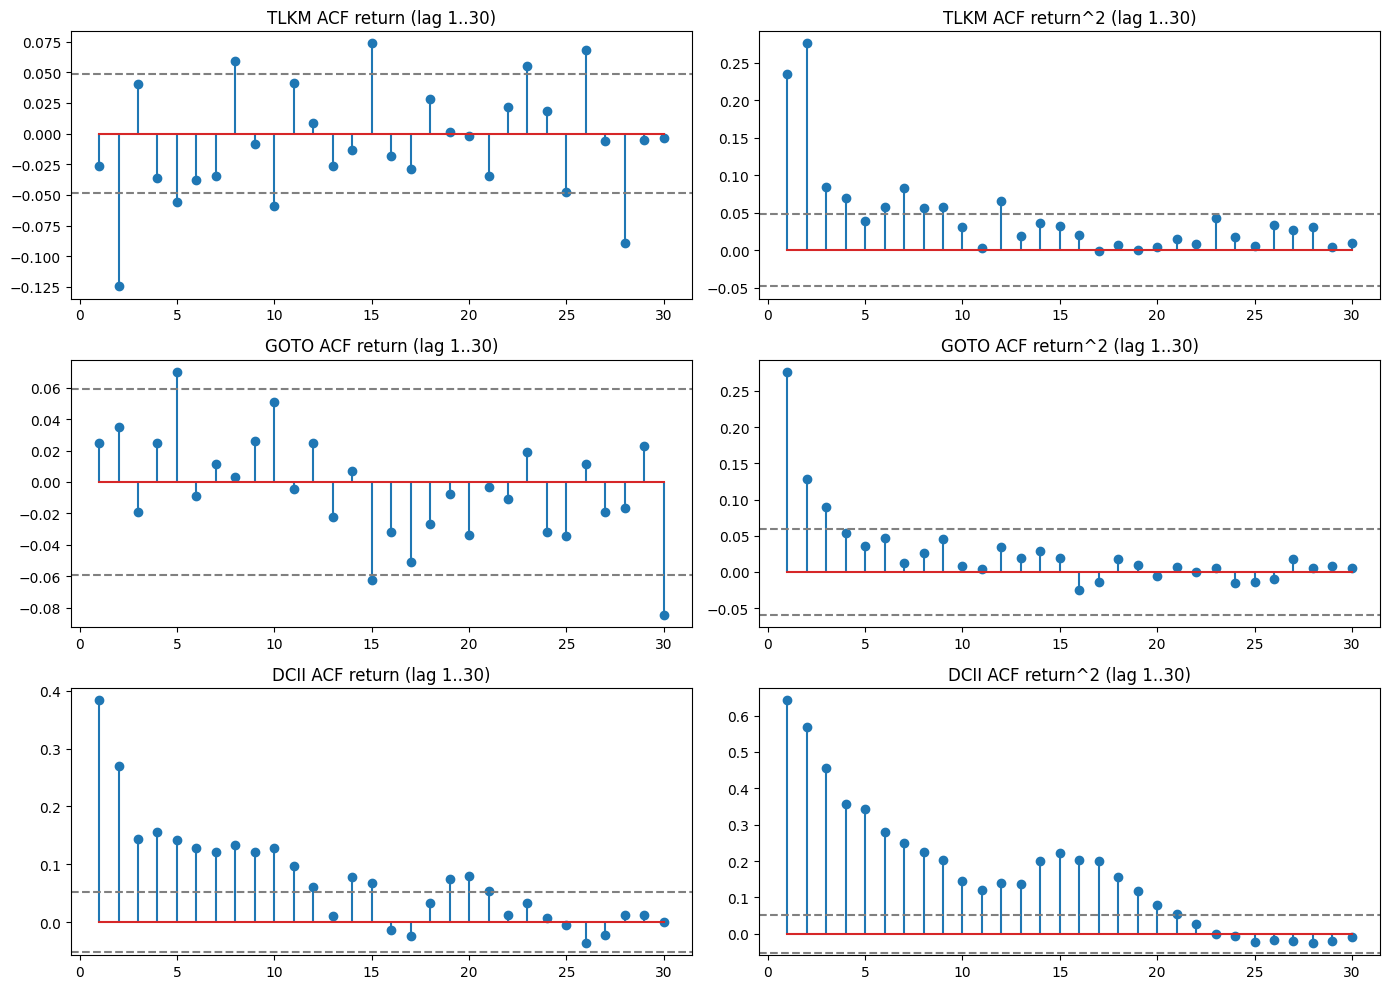


 TLKM base rate (full sample)
          h7    h30
0.03  0.466  0.735
0.05  0.265  0.588
0.07  0.148  0.464
0.10  0.069  0.300
0.15  0.021  0.128
0.20  0.010  0.062
TLKM per year h7 threshold 0.05: {2020: 0.351, 2021: 0.142, 2022: 0.175, 2023: 0.079, 2024: 0.359, 2025: 0.314, 2026: 0.48}
TLKM per year h30 threshold 0.1: {2020: 0.376, 2021: 0.105, 2022: 0.211, 2023: 0.054, 2024: 0.439, 2025: 0.322, 2026: 0.709}

 GOTO base rate (full sample)
          h7    h30
0.03  0.678  0.825
0.05  0.526  0.754
0.07  0.393  0.689
0.10  0.257  0.615
0.15  0.122  0.449
0.20  0.049  0.295
GOTO per year h7 threshold 0.05: {2022: 0.777, 2023: 0.573, 2024: 0.498, 2025: 0.479, 2026: 0.333}
GOTO per year h30 threshold 0.1: {2022: 0.816, 2023: 0.695, 2024: 0.57, 2025: 0.551, 2026: 0.451}

 DCII base rate (full sample)
          h7    h30
0.03  0.441  0.726
0.05  0.300  0.596
0.07  0.199  0.507
0.10  0.097  0.376
0.15  0.046  0.220
0.20  0.021  0.106
DCII per year h7 threshold 0.05: {2021: 0.359, 2022: 0.195,

In [11]:
# Long holiday gaps in TLKM (>5 calendar days)
ref = pd.Series(D["TLKM"].index); g = ref.diff().dt.days
print(pd.DataFrame({"from": ref.shift(1)[g>5].dt.date.values, "to": ref[g>5].dt.date.values,
                    "days": g[g>5].astype(int).values}).to_string(index=False))

# Proper ACF (lags 1..30, 95% band) + robustness checks
def sig(x, n=30):
    a = acf(x, nlags=n)[1:]; b = 1.96/np.sqrt(len(x))
    return [i+1 for i, v in enumerate(a) if abs(v) > b], a
shock = lambda s: s[~(((s.index >= "2020-02-01") & (s.index <= "2020-06-30")) | (s.index >= "2026-01-01"))]
fig, ax = plt.subplots(3, 2, figsize=(14, 10))
for i, (t, a) in enumerate(D.items()):
    r = a.ret.dropna()
    for j, (nm, x) in enumerate([("return", r), ("return^2", r**2)]):
        lags, v = sig(x)
        b = 1.96/np.sqrt(len(x))
        ax[i,j].stem(range(1, 31), v); ax[i,j].axhline(b, ls="--", c="gray"); ax[i,j].axhline(-b, ls="--", c="gray")
        ax[i,j].set_title(f"{t} ACF {nm} (lag 1..30)")
        print(t, nm, "| significant lags:", lags, "| lag1=%.3f lag2=%.3f" % (v[0], v[1]))
    w = r.clip(r.quantile(.01), r.quantile(.99))
    print(t, "return winsorized 1/99%  | significant lags:", sig(w)[0])
    print(t, "return ex COVID & 2026   | significant lags:", sig(shock(r))[0])
    if t == "DCII":
        tr = a.loc[a.traded, "close"]; print(t, "return traded days only  | significant lags:", sig(np.log(tr).diff().dropna())[0])
plt.tight_layout(); plt.show()

# M3 base rate grid (adjusted low) + year-by-year stability
thr = [0.03, 0.05, 0.07, 0.10, 0.15, 0.20]
def target(a, h, th):
    fwd = pd.concat([a.low.shift(-i) for i in range(1, h+1)], axis=1).min(axis=1, skipna=False)
    return (fwd <= (1-th)*a.close)[fwd.notna()]
for t, a in D.items():
    grid = pd.DataFrame({f"h{h}": [target(a, h, th).mean() for th in thr] for h in (7, 30)}, index=thr)
    print("\n", t, "base rate (full sample)\n", grid.round(3))
    for h, th in [(7, 0.05), (30, 0.10)]:
        y = target(a, h, th); print(t, f"per year h{h} threshold {th}:", y.groupby(y.index.year).mean().round(3).to_dict())

# ^JKSE excluding unfinalized candle + GOTO price range
m = yf.download("^JKSE", start="2020-01-01", auto_adjust=False, progress=False)
m.columns = m.columns.get_level_values(0); m = m[m.index < "2026-11-11"]
print("^JKSE rows:", len(m), "| latest:", m.index.max().date())
goto_close = D["GOTO"]["close"]
print("GOTO close min/median/max (adjusted):",
      round(goto_close.min(), 1),
      round(goto_close.median(), 1),
      round(goto_close.max(), 1))

Objectives of the code below:
Permutation test: rMAE ≈ 1, AUC ≈ 0.5, BSS ≤ 0, and GARCH rel_const ≈ 1. Otherwise, there is data leakage in the code.

M1: rMAE below 1 is meaningful only if consistent across tickers and years (years_won column). With ~110 overlapping evaluation points, a 1–2% difference proves nothing.

M2: GARCH or EWMA rel_const below 1 for TLKM is concrete evidence of volatility clustering. This is the success criterion defined before viewing the results.

M3: Positive BSS and AUC well above 0.5 on an adequate sample size. If vol_implied matches XGB, M3 is fundamentally a function of volatility.
80% interval coverage: roughly between 70% and 90%. Empirical intervals tend to be too narrow during regime shifts.

In [12]:
%%writefile kairos_walkforward.py
import numpy as np, pandas as pd, warnings, xgboost as xgb
from arch import arch_model
from statsmodels.tsa.arima.model import ARIMA
from scipy.stats import norm
from sklearn.metrics import roc_auc_score
warnings.filterwarnings("ignore")

BURN = {"TLKM": 0, "GOTO": 120, "DCII": 120}   # burn-in for recently-IPO'd stocks
INIT, STEP, HS, S0 = 500, 10, (7, 30), 60
ORDERS = [(1, 0, 0), (2, 0, 0), (1, 0, 1)]
GRID = [0.03, 0.05, 0.07, 0.10, 0.15, 0.20, 0.25]
Z80 = 1.2816

def feats(r, jr):
    s, j = pd.Series(r), pd.Series(jr)
    cs = s.cumsum()
    return pd.DataFrame({
        "r0": s, "r1": s.shift(1), "r2": s.shift(2), "r4": s.shift(4),
        "mom5": s.rolling(5).sum(), "mom20": s.rolling(20).sum(),
        "vol5": s.rolling(5).std(), "vol20": s.rolling(20).std(), "vol60": s.rolling(60).std(),
        "absr5": s.abs().rolling(5).mean(),
        "ewma": np.sqrt((s**2).ewm(alpha=0.06, adjust=False).mean()),
        "dd60": cs - cs.rolling(60).max(),
        "j0": j, "j5": j.rolling(5).sum(), "jvol20": j.rolling(20).std()}).values

def labels(r, h):
    N = len(r); cs = np.concatenate([[0], np.cumsum(r)]); c2 = np.concatenate([[0], np.cumsum(r**2)])
    y1, rv, mdd = (np.full(N, np.nan) for _ in range(3))
    for s in range(N - h):                      # label for row s uses r[s+1 .. s+h]
        y1[s] = cs[s+h+1] - cs[s+1]
        rv[s] = (c2[s+h+1] - c2[s+1]) / h
        mdd[s] = np.min(cs[s+2:s+h+2] - cs[s+1])  # deepest cumulative drawdown (close-to-close)
    return y1, rv, mdd

def snap(x):
    return min(GRID, key=lambda g: abs(g - x))

def ewma_var(x, lam=0.94):
    v = np.var(x[:20])
    for e in x: v = lam*v + (1-lam)*e*e
    return v

def classics(x, hmax):
    o = {}
    try:
        res = arch_model(x*100, mean="Zero", vol="GARCH", p=1, q=1, dist="t").fit(disp="off", show_warning=False)
        o["gv"] = res.forecast(horizon=hmax, reindex=False).variance.values[-1] / 1e4; o["g_ok"] = 1
    except Exception:
        o["gv"] = np.full(hmax, ewma_var(x)); o["g_ok"] = 0
    best = None
    for od in ORDERS:
        try:
            f = ARIMA(x*100, order=od, trend="n").fit()
            if best is None or f.aic < best[0]: best = (f.aic, f, od)
        except Exception: pass
    o["acum"] = np.cumsum(best[1].forecast(hmax)/100) if best else np.zeros(hmax)
    o["order"] = str(best[2]) if best else "none"
    return o

def xgb_r():
    return xgb.XGBRegressor(n_estimators=150, max_depth=3, learning_rate=0.03, subsample=0.8,
                            colsample_bytree=0.8, min_child_weight=10, random_state=0, verbosity=0, n_jobs=2)

def xgb_c():
    return xgb.XGBClassifier(n_estimators=150, max_depth=3, learning_rate=0.03, subsample=0.8,
                             colsample_bytree=0.8, min_child_weight=10, random_state=0, verbosity=0, n_jobs=2)

def walk(t, r, jr, idx, step=STEP):
    N = len(r); F = feats(r, jr)
    L = {h: labels(r, h) for h in HS}
    sd0 = r[:INIT].std()
    THR = {h: snap(0.85 * sd0 * np.sqrt(h)) for h in HS}      # a priori M3 threshold from the first 500 days
    rows = []
    for i in range(INIT-1, N-1-min(HS), step):
        x = r[:i+1]; c = classics(x, max(HS)); ev = ewma_var(x)
        for h in HS:
            if i + h > N - 1: continue
            y1, rv, mdd = L[h]
            tr = np.arange(S0, i - h + 1)                      # STRICT EMBARGO: s <= i - h
            tr = tr[~np.isnan(F[tr]).any(1) & ~np.isnan(y1[tr])]
            Xtr, Xte = F[tr], F[i:i+1]
            gvar = c["gv"][:h].mean()
            row = dict(ticker=t, h=h, date=idx[i], y1=y1[i], rv=rv[i], mdd=mdd[i], thr=THR[h],
                       a_hat=c["acum"][h-1], v_roll_h=np.mean(x[-h:]**2), v_roll20=np.mean(x[-20:]**2),
                       v_ewma=ev, v_const=np.mean(x**2), v_garch=gvar, g_ok=c["g_ok"], order=c["order"])
            # Leak-free empirical interval (only s <= i-h)
            hist = y1[np.arange(0, i-h+1)][-750:]; hc = hist - hist.mean()
            row["q10"], row["q90"] = np.quantile(hc, .1), np.quantile(hc, .9)
            # M3: label, training base rate, vol-implied
            ytr3 = (mdd[tr] <= np.log(1 - THR[h])).astype(int)
            row["y3"] = int(mdd[i] <= np.log(1 - THR[h])); row["p_base"] = ytr3.mean()
            sg = np.sqrt(gvar); b = np.log(1 - THR[h]) - 0.5826*sg
            row["p_vol"] = min(1.0, 2*norm.cdf(b / (sg*np.sqrt(h))))
            # XGBoost (with embargo)
            row["x_y1"] = xgb_r().fit(Xtr, y1[tr]).predict(Xte)[0]
            ly = np.log(np.maximum(rv[tr], 1e-6)); m2 = xgb_r().fit(Xtr, ly)
            row["x_rv"] = np.exp(m2.predict(Xte)[0]) * np.mean(np.exp(ly - m2.predict(Xtr)))
            row["x_p3"] = xgb_c().fit(Xtr, ytr3).predict_proba(Xte)[0, 1] if 0 < ytr3.mean() < 1 else ytr3.mean()
            rows.append(row)
    return pd.DataFrame(rows)

def qlike(rv, f):
    a, b = np.maximum(rv, 1e-6), np.maximum(f, 1e-6)
    return a/b - np.log(a/b) - 1

def cmp(lm, lb, yrs):
    d = pd.DataFrame({"y": yrs, "m": lm, "b": lb}).groupby("y").mean()
    return dict(win_origin=np.mean(lm < lb), years_won=f"{int((d.m < d.b).sum())}/{len(d)}")

def report(R):
    o1, o2, o3, o4 = [], [], [], []
    for (t, h), g in R.groupby(["ticker", "h"]):
        yrs = g.date.dt.year.values; y = g.y1.values; ab = np.abs(y)
        for nm, p in [("ARIMA", g.a_hat.values), ("XGB", g.x_y1.values)]:
            e = np.abs(y - p); nz = y != 0
            o1.append(dict(ticker=t, h=h, model=nm, n=len(y), MAE_naive0=ab.mean(), MAE=e.mean(), rMAE=e.mean()/ab.mean(),
                           dir_acc=np.mean(np.sign(p[nz]) == np.sign(y[nz])), base_up=np.mean(y[nz] > 0),
                           **cmp(e, ab, yrs)))
        for nm, lo, hi in [("naive+empirical", g.q10.values, g.q90.values),
                           ("naive+GARCH", -Z80*np.sqrt(g.v_garch*h), Z80*np.sqrt(g.v_garch*h))]:
            o4.append(dict(ticker=t, h=h, interval=nm, coverage80=np.mean((y >= lo) & (y <= hi)), width=np.mean(hi-lo)))
        rv = g.rv.values; qb = qlike(rv, g.v_roll_h.values); qc = qlike(rv, g.v_const.values)
        for nm, col in [("naive_roll_h", "v_roll_h"), ("const_var", "v_const"), ("roll20", "v_roll20"), ("EWMA", "v_ewma"), ("GARCH", "v_garch"), ("XGB", "x_rv")]:
            q = qlike(rv, g[col].values)
            o2.append(dict(ticker=t, h=h, model=nm, n=len(rv), QLIKE=q.mean(), rel_const=q.mean()/qc.mean(),
                           **(cmp(q, qb, yrs) if nm != "naive_roll_h" else {})))
        y3 = g.y3.values; bb = (g.p_base.values - y3)**2
        for nm, col in [("base_rate", "p_base"), ("vol_implied", "p_vol"), ("XGB", "x_p3")]:
            p = g[col].values; br = (p - y3)**2
            auc = roc_auc_score(y3, p) if 0 < y3.mean() < 1 and nm != "base_rate" else np.nan
            o3.append(dict(ticker=t, h=h, model=nm, thr=g.thr.iloc[0], n=len(y3), event_rate=y3.mean(), Brier=br.mean(),
                           BSS=1 - br.mean()/bb.mean(), AUC=auc, **(cmp(br, bb, yrs) if nm != "base_rate" else {})))
    f = lambda d: print(pd.DataFrame(d).round(4).to_string(index=False))
    print("\n== M1 (h-day cumulative return; rMAE<1 = better than naive zero) =="); f(o1)
    print("\n== M1 interval (nominal 80%) =="); f(o4)
    print("\n== M2 (QLIKE on h-day realized variance; win_* vs naive_roll_h; rel_const<1 = better than constant variance) =="); f(o2)
    print("\n== M3 (Brier skill vs base rate; BSS>0 = better) =="); f(o3)
    print("\nGARCH failed to converge:", int((R.g_ok == 0).sum()), "of", len(R), "| ARIMA order:", R["order"].value_counts().to_dict())

Writing kairos_walkforward.py

In [13]:
exec(open("kairos_walkforward.py").read())

jk = yf.download("^JKSE", start="2020-01-01", auto_adjust=False, progress=False)
jk.columns = jk.columns.get_level_values(0); jk = jk["Close"]
jk.index = pd.to_datetime(jk.index).tz_localize(None); jk = jk[jk.index < "2026-11-11"]

R_all = []
for t, a in D.items():
    a = a.iloc[BURN[t]:]
    r = np.log(a.close).diff().dropna()
    j = np.log(jk.reindex(a.index).ffill()).diff().reindex(r.index).fillna(0)
    R_all.append(walk(t, r.values, j.values, r.index))
    print(t, "done", flush=True)
R = pd.concat(R_all, ignore_index=True)
report(R)

# Permutation test (must collapse to naive level)
t = "TLKM"; a = D[t]; r = np.log(a.close).diff().dropna()
j = np.log(jk.reindex(a.index).ffill()).diff().reindex(r.index).fillna(0)
rng = np.random.default_rng(0)
Rp = walk("TLKM_perm", rng.permutation(r.values), rng.permutation(j.values), r.index, step=20)
report(Rp)

# Two pending GOTO checks
g = D["GOTO"]; z = (g.ret.dropna() == 0).astype(int)
run = z.groupby((z != z.shift()).cumsum()).cumsum()
print("GOTO longest return=0 run:", int(run.max()), "days, ending", run.idxmax().date())
print(g[["close", "volume", "ret"]].tail(25).round(4))
print(g.volume.nlargest(5))

TLKM done
GOTO done
DCII done

== M1 (h-day cumulative return; rMAE<1 = better than naive zero) ==
ticker  h model   n  MAE_naive0    MAE   rMAE  dir_acc  base_up  win_origin    years_won
  DCII  7 ARIMA  78      0.0502 0.0506 1.0071   0.5600   0.3733      0.4744          2/4
  DCII  7   XGB  78      0.0502 0.0655 1.3044   0.5067   0.3733      0.3718          1/4
  DCII 30 ARIMA  76      0.1555 0.1534 0.9864   0.6133   0.4533      0.5395          3/4
  DCII 30   XGB  76      0.1555 0.2073 1.3330   0.4000   0.4533      0.3421          1/4
  GOTO  7 ARIMA  47      0.0579 0.0579 0.9991   0.4571   0.4286      0.3191          2/3
  GOTO  7   XGB  47      0.0579 0.0670 1.1578   0.4857   0.4286      0.3191          0/3
  GOTO 30 ARIMA  45      0.1192 0.1192 1.0001   0.3421   0.3421      0.2889          1/3
  GOTO 30   XGB  45      0.1192 0.1377 1.1553   0.5263   0.3421      0.3778          1/3
  TLKM  7 ARIMA 115      0.0351 0.0348 0.9910   0.5702   0.5526      0.5565          3/5
  TLKM  7  